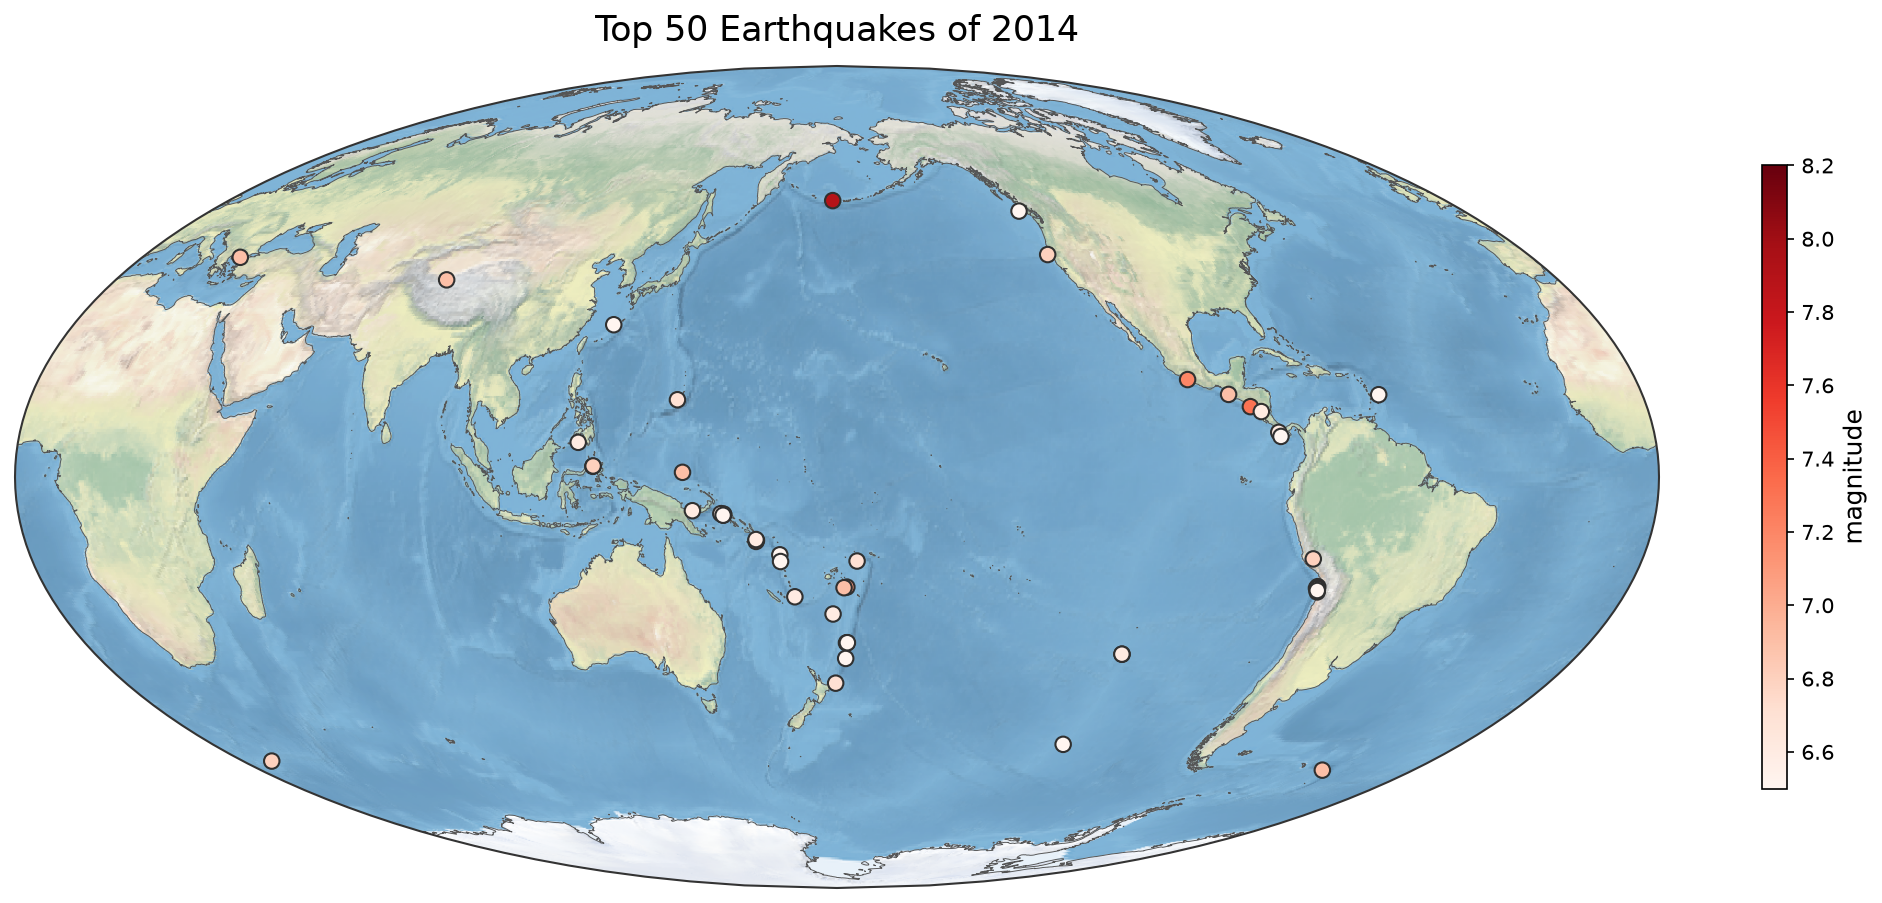

Number of earthquakes: 50
Minimum magnitude: 6.5
Maximum magnitude: 8.2


In [6]:
#1.在本套习题中，我们将使用来自美国地质调查局（USGS）地震数据库的文件。请使用提供的文件（usgs_earthquakes.csv）重新绘制下图。请将“mag”列作为震级
import numpy as np
import xarray as xr
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import cartopy.crs as ccrs
import cartopy.feature as cfeature
%matplotlib inline
df = pd.read_csv('usgs_earthquakes.csv')
df['time'] = pd.to_datetime(df['time'], utc=True, errors='coerce')

for col in ['mag', 'longitude', 'latitude']: df[col] = pd.to_numeric(df[col], errors='coerce')
subset = df.loc[(df['time'].dt.year == 2014) &(df['type'] == 'earthquake')].dropna(subset=['mag', 'longitude', 'latitude'])
top50 = subset.nlargest(50, 'mag')

fig = plt.figure(figsize=(14, 7), dpi=150)
ax = fig.add_subplot(111,projection=ccrs.Mollweide(central_longitude=180))
ax.set_global()
ax.stock_img()
ax.coastlines(resolution='50m',linewidth=0.45,color='#555555',zorder=2)
#吸取了颜色的代码..
ax.spines['geo'].set_linewidth(1.0)
ax.spines['geo'].set_edgecolor('#333333')

pts = ax.scatter(top50['longitude'],top50['latitude'],c=top50['mag'],s=55,cmap='Reds',vmin=6.5,vmax=8.2,edgecolors='#303030',linewidths=1.0,transform=ccrs.PlateCarree(),zorder=5)
cbar = fig.colorbar(pts,ax=ax,shrink=0.62,pad=0.05,aspect=25)
cbar.set_label('magnitude', fontsize=12)
cbar.set_ticks(np.arange(6.6, 8.21, 0.2))
cbar.ax.tick_params(labelsize=10)

ax.set_title('Top 50 Earthquakes of 2014',fontsize=17,pad=12)

plt.tight_layout()
plt.savefig('usgs_2014_top50_high_resolution.png',dpi=300,bbox_inches='tight',facecolor='white')
plt.show()

print('Number of earthquakes:', len(top50))
print('Minimum magnitude:', top50['mag'].min())
print('Maximum magnitude:', top50['mag'].max())


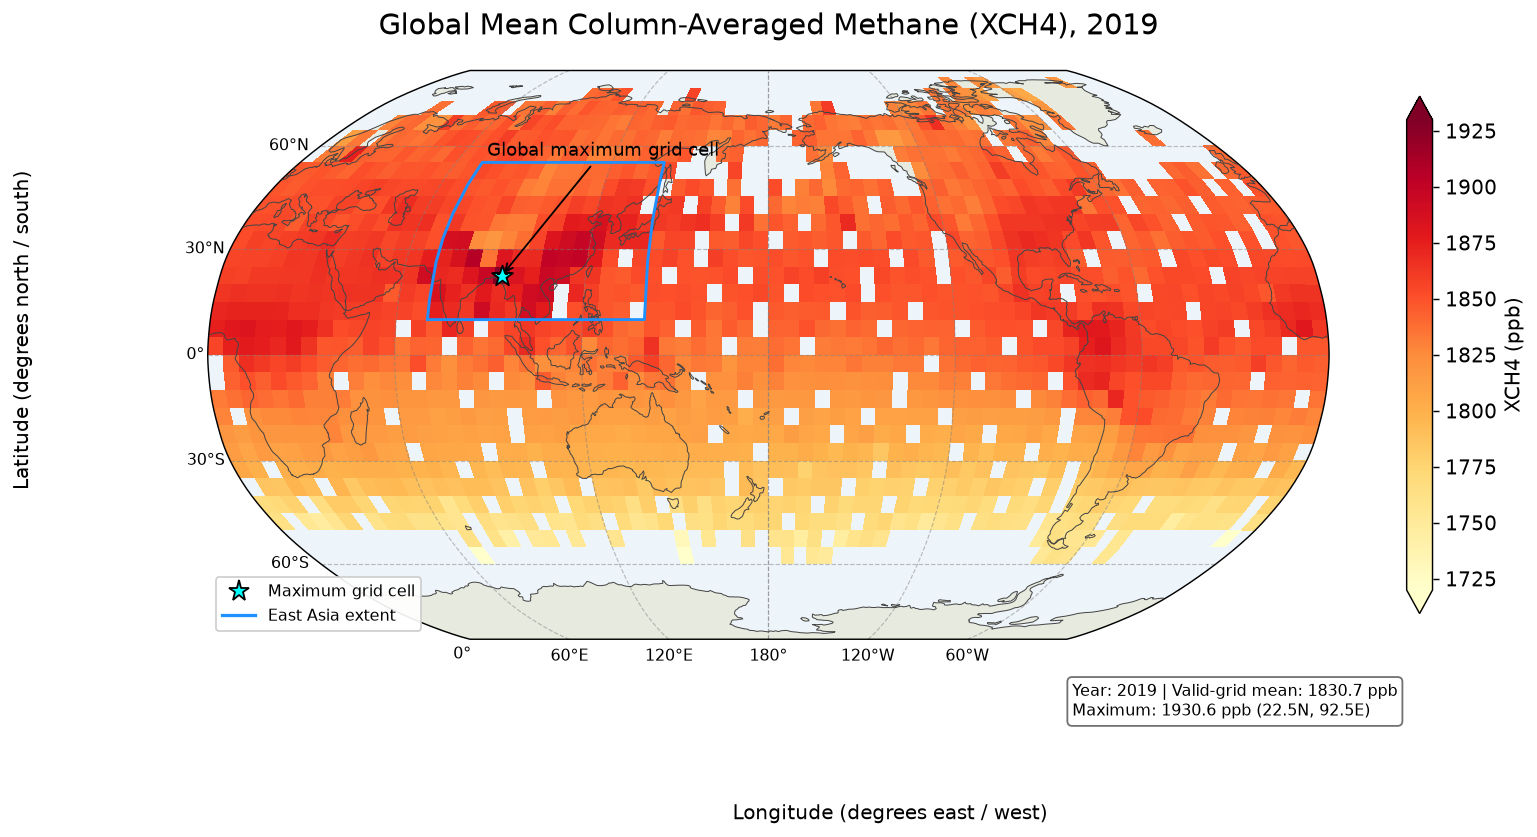

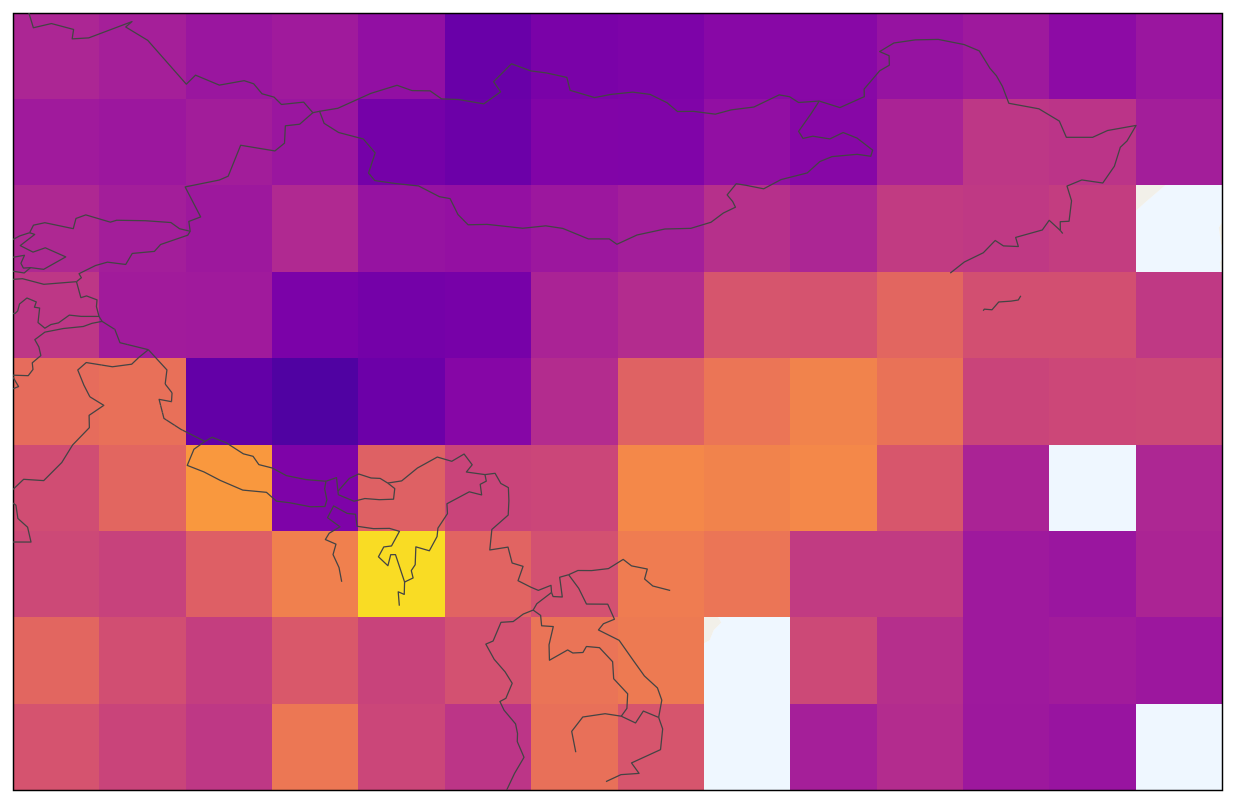

In [9]:
#浏览美国宇航局戈达德地球科学数据与信息服务中心（GES DISC）的网站。搜索并下载你感兴趣的数据集。你也可以在本习题集中使用本小组的数据。但数据集应为 netCDF 格式。对于本习题集，你可以使用与作业 03 中相同的数据集。2.1 [10 分] 绘制某个变量的全球图。图中应包含：项目、x 轴标签和刻度、y 轴标签和刻度、标题、网格线、图例、色条、掩膜或特征、注释以及文本框（每项 1 分）。2.2 [10 分] 绘制同一变量的区域图。图中应包含：不同的项目、x 轴标签和刻度、y 轴标签和刻度、标题、网格线、图例、色标、掩膜或特征、注释以及文本框（每项 1 分）。
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import cartopy.crs as ccrs
import cartopy.feature as cfeature
ds = xr.open_dataset('200301_202006-C3S-L3_GHG-PRODUCTS-OBS4MIPS-MERGED-v4.3.nc')
raw = ds['xch4']

raw = raw.where(np.isfinite(raw) & (raw > 1e-6) & (raw < 1e-4))
ch4 = (raw.sel(time=slice('2019-01-01', '2019-12-31')).mean('time', skipna=True) * 1e9)
ch4.attrs['units'] = 'ppb'
lon, lat = ds['lon'].values, ds['lat'].values
valid = ch4.values
imax = np.nanargmax(valid)
i, j = np.unravel_index(imax, valid.shape)
peak_lat, peak_lon, peak_val = float(lat[i]), float(lon[j]), float(valid[i, j])
mean_val = float(ch4.mean(skipna=True))
plt.rcParams.update({'font.size': 11, 'axes.titlesize': 16, 'savefig.dpi': 300})
geo = ccrs.PlateCarree()

fig = plt.figure(figsize=(14, 7.6), dpi=130)
ax = fig.add_subplot(111, projection=ccrs.Robinson(central_longitude=180))
ax.set_global()
ax.add_feature(cfeature.OCEAN.with_scale('110m'), facecolor='#edf4fa', zorder=0)
ax.add_feature(cfeature.LAND.with_scale('110m'), facecolor='#e7ebdf', zorder=0)
mesh = ax.pcolormesh(lon, lat, ch4.values, transform=geo, shading='auto',
                     cmap='YlOrRd', vmin=1720, vmax=1930, zorder=2)
ax.coastlines(resolution='110m', linewidth=0.55, color='#444444', zorder=3)
lines = ax.gridlines(crs=geo, draw_labels=True, x_inline=False, y_inline=False,linewidth=0.65, color='gray', alpha=0.5, linestyle='--')
lines.top_labels = False
lines.right_labels = False
lines.xlocator = mticker.FixedLocator(np.arange(-180, 181, 60))
lines.ylocator = mticker.FixedLocator(np.arange(-60, 61, 30))
lines.xlabel_style = {'size': 9}
lines.ylabel_style = {'size': 9}
ax.set_title('Global Mean Column-Averaged Methane (XCH4), 2019', pad=20)

region_lon = [70, 140, 140, 70, 70]
region_lat = [10, 10, 55, 55, 10]
ax.plot(region_lon, region_lat, transform=geo, color='dodgerblue',
        linewidth=1.6, zorder=5)
ax.scatter([peak_lon], [peak_lat], transform=geo, marker='*', s=145,
           facecolor='cyan', edgecolor='black', zorder=6)
ax.annotate('Global maximum grid cell',
            xy=(peak_lon, peak_lat), xycoords=geo._as_mpl_transform(ax),
            xytext=(70, 57), textcoords=geo._as_mpl_transform(ax),
            arrowprops={'arrowstyle': '->', 'color': 'black', 'lw': 1},
            fontsize=10, color='black', zorder=7)
ax.legend(handles=[Line2D([], [], marker='*', color='none', markerfacecolor='cyan',
                          markeredgecolor='black', markersize=12, label='Maximum grid cell'),
                   Line2D([], [], color='dodgerblue', lw=1.8, label='East Asia extent')],
          loc='lower left', fontsize=9, framealpha=0.92)
cb = fig.colorbar(mesh, ax=ax, orientation='vertical', shrink=0.68,
                  pad=0.055, extend='both')
cb.set_label('XCH4 (ppb)')
fig.text(0.60, 0.13,
         f'Year: 2019 | Valid-grid mean: {mean_val:.1f} ppb\n'
         f'Maximum: {peak_val:.1f} ppb ({peak_lat:.1f}N, {peak_lon:.1f}E)',
         fontsize=9, bbox={'boxstyle': 'round', 'fc': 'white', 'ec': '#666666', 'alpha': 0.93})
fig.text(0.50, 0.025, 'Longitude (degrees east / west)', ha='center')
fig.text(0.018, 0.52, 'Latitude (degrees north / south)', va='center', rotation=90)
fig.savefig('PS4_2_1_Global_XCH4_2019.png', dpi=300, bbox_inches='tight')
plt.show()

#2.2
region = ch4.sel(lon=slice(70, 140), lat=slice(10, 55))
arr = region.values
ri, rj = np.unravel_index(np.nanargmax(arr), arr.shape)
r_lat = float(region.lat.values[ri]); r_lon = float(region.lon.values[rj])
r_peak = float(arr[ri, rj]); r_mean = float(region.mean(skipna=True))
fig = plt.figure(figsize=(12, 8), dpi=130)
ax = fig.add_subplot(111, projection=geo)
ax.set_extent([70, 140, 10, 55], crs=geo)
#检索了常见颜色代码 课上给的不够
ax.add_feature(cfeature.OCEAN.with_scale('110m'), facecolor='#eff7ff', zorder=0)
ax.add_feature(cfeature.LAND.with_scale('110m'), facecolor='#f2f0e9', zorder=0)
mesh2 = ax.pcolormesh(lon, lat, ch4.values, transform=geo, shading='auto',cmap='plasma', vmin=1800, vmax=1940, zorder=2)
ax.add_feature(cfeature.BORDERS.with_scale('110m'), edgecolor='#444444',linewidth=0.7, zorder=4)